In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# input dari Data Preparation, pembagian train dan test tetap sama
data = pd.read_csv("../data/kbbi_bersih.csv")
data["contoh"] = data["contoh"].fillna("")
data["suku_kata"] = data["nama"].str.count(r"\.") + 1
data["huruf"] = data["nama"].str.replace(".", "", regex=False).str.len()
data["panjang_makna"] = data["submakna"].str.len()
data["jumlah_kata_makna"] = data["submakna"].str.split().str.len()
data["ada_contoh"] = (data["contoh"] != "").astype(int)

# 20.000 data latih saja supaya 100 pohon bisa dilatih dengan cepat
train = data[data["split"] == "train"].sample(20000, random_state=42)
test = data[data["split"] == "test"]
y_train, y_test = train["kelas_utama"], test["kelas_utama"]

# fitur: 5 fitur angka dan 300 kata terpenting dari teks makna
num_cols = ["suku_kata", "huruf", "panjang_makna", "jumlah_kata_makna", "ada_contoh"]
pre = ColumnTransformer([("angka", "passthrough", num_cols),
                         ("kata", TfidfVectorizer(max_features=300, min_df=5), "submakna")])
X_train = pre.fit_transform(train)
X_test = pre.transform(test)
fitur = [f.split("__")[1] for f in pre.get_feature_names_out()]
print(X_train.shape, X_test.shape)

(20000, 305) (19857, 305)


In [2]:
# decision tree: model seperti flowchart, dibatasi 3 tingkat supaya aturannya terbaca
pohon_kecil = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
print(export_text(pohon_kecil, feature_names=fitur))

|--- yang <= 0.02
|   |--- ada_contoh <= 0.50
|   |   |--- huruf <= 7.50
|   |   |   |--- class: Nomina
|   |   |--- huruf >  7.50
|   |   |   |--- class: Nomina
|   |--- ada_contoh >  0.50
|   |   |--- suku_kata <= 2.50
|   |   |   |--- class: Adjektiva
|   |   |--- suku_kata >  2.50
|   |   |   |--- class: Verba
|--- yang >  0.02
|   |--- ada_contoh <= 0.50
|   |   |--- tentang <= 0.31
|   |   |   |--- class: Nomina
|   |   |--- tentang >  0.31
|   |   |   |--- class: Nomina
|   |--- ada_contoh >  0.50
|   |   |--- huruf <= 7.50
|   |   |   |--- class: Nomina
|   |   |--- huruf >  7.50
|   |   |   |--- class: Nomina



In [3]:
# masalah satu decision tree: dibiarkan tumbuh sampai menghafal data latih (overfitting)
t = time.time()
pohon = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
waktu_pohon = time.time() - t

print(f"Kedalaman: {pohon.get_depth()} | Jumlah daun: {pohon.get_n_leaves():,}")
print(f"Akurasi latih: {accuracy_score(y_train, pohon.predict(X_train)):.1%}")
print(f"Akurasi uji: {accuracy_score(y_test, pohon.predict(X_test)):.1%}")

Kedalaman: 99 | Jumlah daun: 4,061
Akurasi latih: 95.3%
Akurasi uji: 75.1%


In [4]:
# random forest: 100 pohon, setiap pohon dilatih pada sampel acak data dan fitur acak
t = time.time()
hutan = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)
waktu_hutan = time.time() - t

print(f"Akurasi latih: {accuracy_score(y_train, hutan.predict(X_train)):.1%}")
print(f"Akurasi uji: {accuracy_score(y_test, hutan.predict(X_test)):.1%}")

Akurasi latih: 95.3%
Akurasi uji: 80.2%


In [5]:
# dua makna kata "random": bootstrap sample (data) dan subset fitur (kolom)
unik = len(np.unique(hutan.estimators_samples_[0])) / len(train)
print(f"Pohon pertama hanya melihat {unik:.1%} data latih yang berbeda")
print(f"Setiap pertanyaan (node) hanya boleh memilih dari {int(np.sqrt(X_train.shape[1]))} dari {X_train.shape[1]} fitur")

Pohon pertama hanya melihat 63.4% data latih yang berbeda
Setiap pertanyaan (node) hanya boleh memilih dari 17 dari 305 fitur


In [6]:
# voting: satu data uji ditanyakan ke setiap pohon
i = 0
makna = test["submakna"].iloc[i]
suara = pd.Series([hutan.classes_[int(p.predict(X_test[i])[0])] for p in hutan.estimators_])

print(f"Data baru: {makna[:70]}")
print("5 pohon pertama:", suara.head(5).tolist())
print(suara.value_counts())
print("Prediksi akhir:", suara.value_counts().idxmax(), "| Kelas sebenarnya:", y_test.iloc[i])

Data baru: ajun komisaris besar
5 pohon pertama: ['Nomina', 'Nomina', 'Nomina', 'Nomina', 'Nomina']
Nomina       97
Verba         2
Adjektiva     1
Name: count, dtype: int64
Prediksi akhir: Nomina | Kelas sebenarnya: Nomina


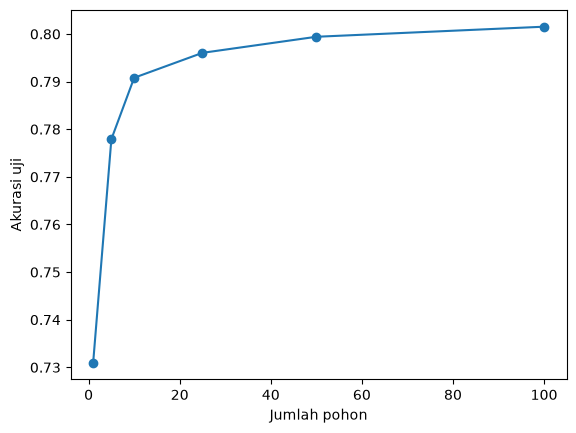

In [7]:
# pengaruh jumlah pohon terhadap akurasi uji (suara n pohon pertama dari hutan yang sama dirata-rata)
jumlah = [1, 5, 10, 25, 50, 100]
proba = [p.predict_proba(X_test) for p in hutan.estimators_]
akurasi = [accuracy_score(y_test, hutan.classes_[np.mean(proba[:n], axis=0).argmax(axis=1)]) for n in jumlah]

plt.plot(jumlah, akurasi, marker="o")
plt.xlabel("Jumlah pohon")
plt.ylabel("Akurasi uji")
plt.show()

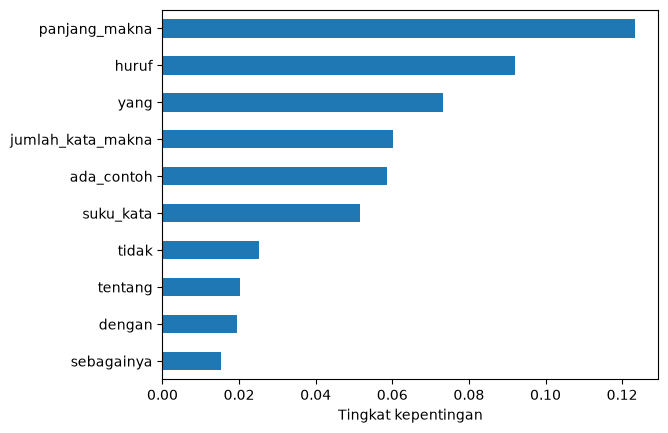

In [8]:
# feature importance: fitur yang paling berpengaruh
penting = pd.Series(hutan.feature_importances_, index=fitur).sort_values().tail(10)
penting.plot.barh()
plt.xlabel("Tingkat kepentingan")
plt.show()

In [9]:
# perbandingan satu pohon dan hutan, termasuk kekurangan hutan (lebih lambat dan lebih berat)
pd.DataFrame({
    "Akurasi latih": [accuracy_score(y_train, pohon.predict(X_train)), accuracy_score(y_train, hutan.predict(X_train))],
    "Akurasi uji": [accuracy_score(y_test, pohon.predict(X_test)), accuracy_score(y_test, hutan.predict(X_test))],
    "Waktu latih (detik)": [waktu_pohon, waktu_hutan],
    "Jumlah pohon": [1, len(hutan.estimators_)],
}, index=["Decision Tree", "Random Forest"]).round(3)

,Akurasi latih,Akurasi uji,Waktu latih (detik),Jumlah pohon
Decision Tree,0.953,0.751,1.128,1
Random Forest,0.953,0.802,2.261,100


### Analisis

Satu decision tree yang dibiarkan tumbuh sedalam 99 tingkat punya akurasi latih 95,3 persen tetapi akurasi uji hanya 75,1 persen, jadi pohon ini menghafal data latih. Random Forest dengan akurasi latih yang sama (95,3 persen) mencapai akurasi uji 80,2 persen, artinya selisih antara latih dan uji menyempit dan model lebih tahan overfitting. Satu pohon sendirian di dalam hutan hanya mencapai 73,1 persen, lalu akurasi naik cepat sampai sekitar 25 pohon (79,6 persen) dan setelah itu kenaikannya kecil. Ini menunjukkan bahwa kekuatan hutan datang dari voting banyak pohon, dan menambah pohon terus menerus tidak selalu sebanding dengan tambahan waktunya.

Pada contoh voting, 97 dari 100 pohon memilih nomina untuk kata baru "ajun komisaris besar", sehingga prediksinya yakin dan benar. Dari feature importance, panjang makna, jumlah huruf, dan kata "yang" menjadi fitur paling berpengaruh, dan kelima fitur angka dari Data Preparation semuanya masuk delapan besar. Harga yang dibayar adalah waktu latih sekitar 13 kali lebih lama dan hilangnya aturan yang jelas seperti pada pohon kecil di awal notebook.

In [10]:
# refleksi: memprediksi serangan jantung dengan 50 fitur pasien
pd.DataFrame({
    "Pertanyaan": ["Risiko 1 pohon", "Solusi Random Forest"],
    "Jawaban": ["Satu pohon menghafal data pasien latih, termasuk kebetulan yang tidak berlaku pada pasien baru, sehingga diagnosis bisa salah total",
                "500 pohon dilatih pada data dan fitur yang berbeda lalu diambil suara terbanyak, jadi kesalahan satu pohon ditutup oleh pohon lain"],
})

,Pertanyaan,Jawaban
0,Risiko 1 pohon,"Satu pohon menghafal data pasien latih, termas..."
1,Solusi Random Forest,500 pohon dilatih pada data dan fitur yang ber...
